In [1]:
%load_ext autoreload
%autoreload 2

# Лаба1 - сравнение рекомендательных моделей на KuaiRec


Цель: сравнить ItemCF, iALS, EASE, FM с метапризнаками и ALS/iALS с кастомным таргетом
на персональных top-10 рекомендациях.


## Запуск

Запускайте ноутбук из `hw1/` в окружении с зависимостями из `requirements.txt`.
Данные: [KuaiRec](https://github.com/chongminggao/KuaiRec). Загрузка из `hw1/`:

```bash
mkdir -p data/raw
curl -L https://zenodo.org/records/18164998/files/KuaiRec.zip -o data/KuaiRec.zip
unzip -q data/KuaiRec.zip -d data/raw
```

Затем выполните все ячейки сверху вниз. Подробности запуска — в [DATA.md](DATA.md).


Нам нужны `big_matrix.csv` с просмотрами и `item_categories.csv` с категориями видео.
`watch_ratio` - доля просмотренного видео, `timestamp` - время просмотра,
`feat` - список категорий.


In [2]:
from pathlib import Path
import random
import sys
import numpy as np
import polars as pl
import torch
import matplotlib.pyplot as plt


SEED = 42
K = 10
DATA_DIR = Path("data")

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False


Загрузка данных


In [3]:
from utils.data import load_csv

interactions = load_csv(DATA_DIR, "big_matrix.csv")
categories = load_csv(DATA_DIR, "item_categories.csv")

print("Interactions:")
print(interactions.head(5))

print("Schema:")
print(interactions.schema)

print("Categories:")
print(categories.head(5))


Interactions:
shape: (5, 8)
┌─────────┬──────────┬─────────────┬─────────────┬─────────────┬──────────┬───────────┬────────────┐
│ user_id ┆ video_id ┆ play_durati ┆ video_durat ┆ time        ┆ date     ┆ timestamp ┆ watch_rati │
│ ---     ┆ ---      ┆ on          ┆ ion         ┆ ---         ┆ ---      ┆ ---       ┆ o          │
│ i64     ┆ i64      ┆ ---         ┆ ---         ┆ str         ┆ i64      ┆ f64       ┆ ---        │
│         ┆          ┆ i64         ┆ i64         ┆             ┆          ┆           ┆ f64        │
╞═════════╪══════════╪═════════════╪═════════════╪═════════════╪══════════╪═══════════╪════════════╡
│ 0       ┆ 3649     ┆ 13838       ┆ 10867       ┆ 2020-07-05  ┆ 20200705 ┆ 1.5939e9  ┆ 1.273397   │
│         ┆          ┆             ┆             ┆ 00:08:23.43 ┆          ┆           ┆            │
│         ┆          ┆             ┆             ┆ 8           ┆          ┆           ┆            │
│ 0       ┆ 9598     ┆ 13665       ┆ 10984       ┆ 2020-07-05  

# EDA и подготовка



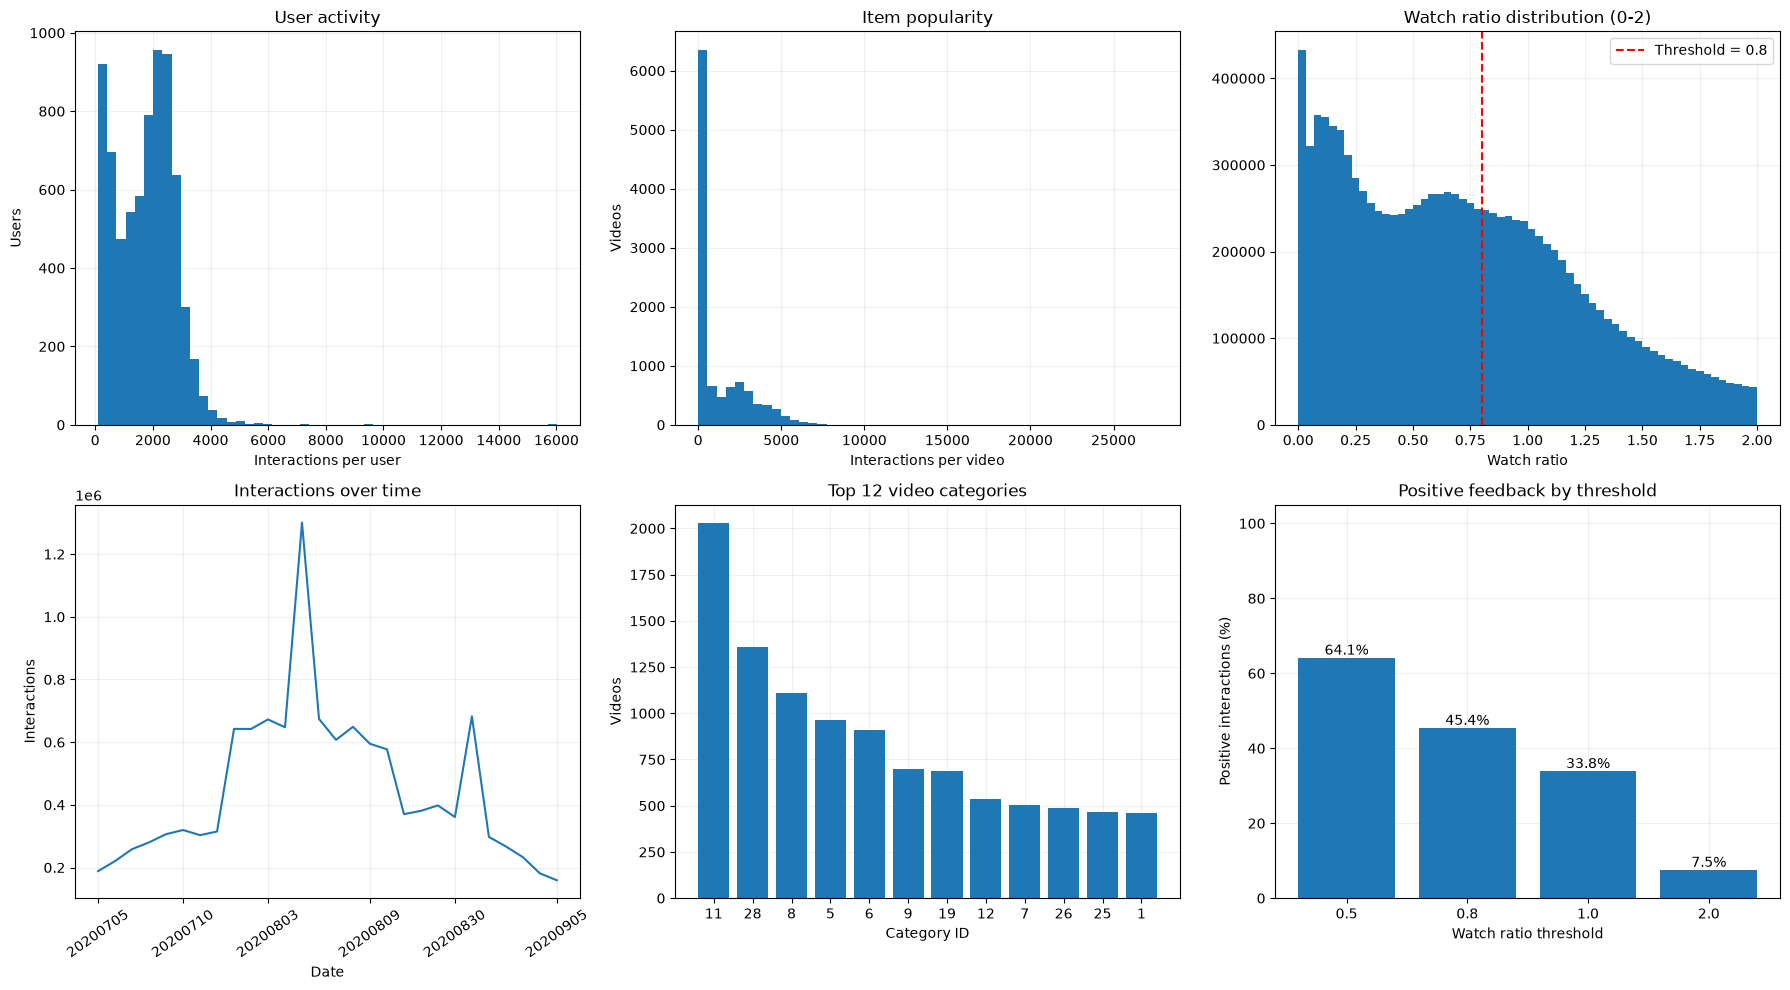

Interactions: 12,530,806
Users: 7,176
Items: 10,728
Unique user-item pairs: 10,300,969
Density: 13.38%
Sparsity: 86.62%


Duplicate rows: 1,931,638
Repeated user-item pairs: 2,229,837
Watch ratio > 2: 7.47%
Unique category tags: 31

Missing values:
shape: (1, 8)
┌─────────┬──────────┬───────────────┬────────────────┬──────┬──────┬───────────┬─────────────┐
│ user_id ┆ video_id ┆ play_duration ┆ video_duration ┆ time ┆ date ┆ timestamp ┆ watch_ratio │
│ ---     ┆ ---      ┆ ---           ┆ ---            ┆ ---  ┆ ---  ┆ ---       ┆ ---         │
│ u32     ┆ u32      ┆ u32           ┆ u32            ┆ u32  ┆ u32  ┆ u32       ┆ u32         │
╞═════════╪══════════╪═══════════════╪════════════════╪══════╪══════╪═══════════╪═════════════╡
│ 0       ┆ 0        ┆ 0             ┆ 0              ┆ 0    ┆ 0    ┆ 0         ┆ 0           │
└─────────┴──────────┴───────────────┴────────────────┴──────┴──────┴───────────┴─────────────┘

Missing metadata values:
shape: (1, 2)
┌──────────┬──────┐
│ video_id ┆ feat │
│ ---      ┆ ---  │
│ u32      ┆ u32  │
╞══════════╪══════╡
│ 0        ┆ 0    │
└──────────┴──────┘


In [4]:

import ast
from collections import Counter

import numpy as np
import polars as pl
import matplotlib.pyplot as plt

# 1. Подготовка статистик
user_activity = (
    interactions.group_by("user_id")
    .len(name="count")
)

item_popularity = (
    interactions.group_by("video_id")
    .len(name="count")
)

watch = interactions["watch_ratio"].drop_nulls().to_numpy()
watch = watch[np.isfinite(watch)]

daily = (
    interactions.group_by("date")
    .len(name="count")
    .sort("date")
)

# Категории видео: feat хранит список тегов
tag_counts = Counter()

for value in categories["feat"].drop_nulls():
    tags = ast.literal_eval(value) if isinstance(value, str) else value
    if isinstance(tags, (list, tuple)):
        tag_counts.update(tags)

# 2. Создаём сетку из 6 графиков
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# График 1: Активность пользователей
axes[0, 0].hist(
    user_activity["count"].to_numpy(),
    bins=50
)
axes[0, 0].set_title("User activity")
axes[0, 0].set_xlabel("Interactions per user")
axes[0, 0].set_ylabel("Users")

# График 2: Популярность видео
axes[0, 1].hist(
    item_popularity["count"].to_numpy(),
    bins=50
)
axes[0, 1].set_title("Item popularity")
axes[0, 1].set_xlabel("Interactions per video")
axes[0, 1].set_ylabel("Videos")

# График 3: Распределение watch_ratio
axes[0, 2].hist(
    watch[(watch >= 0) & (watch <= 2)],
    bins=60
)
axes[0, 2].axvline(0.8, color="red", linestyle="--",
                   label="Threshold = 0.8")
axes[0, 2].set_title("Watch ratio distribution (0-2)")
axes[0, 2].set_xlabel("Watch ratio")
axes[0, 2].legend()

# График 4: Активность во времени
x = np.arange(daily.height)
axes[1, 0].plot(x, daily["count"].to_numpy())

ticks = np.linspace(0, daily.height - 1, 6, dtype=int)
axes[1, 0].set_xticks(
    ticks,
    [str(daily["date"][int(i)]) for i in ticks],
    rotation=35
)
axes[1, 0].set_title("Interactions over time")
axes[1, 0].set_xlabel("Date")
axes[1, 0].set_ylabel("Interactions")

# График 5: Самые распространённые категории
top_tags = tag_counts.most_common(12)

axes[1, 1].bar(
    [str(tag) for tag, count in top_tags],
    [count for tag, count in top_tags]
)
axes[1, 1].set_title("Top 12 video categories")
axes[1, 1].set_xlabel("Category ID")
axes[1, 1].set_ylabel("Videos")

# График 6: Доля положительных реакций
thresholds = [0.5, 0.8, 1.0, 2.0]
positive_rates = [
    np.mean(watch >= threshold) * 100
    for threshold in thresholds
]

bars = axes[1, 2].bar(
    [str(t) for t in thresholds],
    positive_rates
)
axes[1, 2].bar_label(bars, fmt="%.1f%%")
axes[1, 2].set_ylim(0, 105)
axes[1, 2].set_title("Positive feedback by threshold")
axes[1, 2].set_xlabel("Watch ratio threshold")
axes[1, 2].set_ylabel("Positive interactions (%)")

for ax in axes.flat:
    ax.grid(alpha=0.2)
    ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

# 3. Сводная статистика
n_users = interactions["user_id"].n_unique()
n_items = interactions["video_id"].n_unique()
n_unique_pairs = interactions.select(
    pl.struct(["user_id", "video_id"]).n_unique()
).item()

print(f"Interactions: {interactions.height:,}")
print(f"Users: {n_users:,}")
print(f"Items: {n_items:,}")
print(f"Unique user-item pairs: {n_unique_pairs:,}")
print(f"Density: {n_unique_pairs / (n_users * n_items):.2%}")
print(f"Sparsity: {1 - n_unique_pairs / (n_users * n_items):.2%}")
print(f"Duplicate rows: {interactions.is_duplicated().sum():,}")
print(f"Repeated user-item pairs: {interactions.height - n_unique_pairs:,}")
print(f"Watch ratio > 2: {np.mean(watch > 2):.2%}")
print(f"Unique category tags: {len(tag_counts)}")

print("\nMissing values:")
print(interactions.null_count())
print("\nMissing metadata values:")
print(categories.null_count())


Так как явного фидбека нет - выберем трешхолд watch_ratio=0.8 - то есть если пользователь посмотрел 80% видео то будем считать рекомендацию данного видео релевантным.

Выбор также обуславливается данными - при таком трешхолде у нас positive rate будет равен примерно 46%, что удобно для нашей задачи.

Более того, не будем рассматривать дубликаты после первого просмотра - то что пользователь вернулся к видео через какое то время может быть определенным сингалом, однако для нашего эксперимента будет лучше не рассматривать повторные интеракции, т.к. одно видео просмотренное давжды не является двумя различными айтемами для рекомендации.

In [5]:
from utils.data import prepare_sample

sample = prepare_sample(
    interactions,
    seed=SEED,
    n_users=2000,
    n_items=1500,
    threshold=0.8
)

print(f"Interactions: {sample.height:,}")
print(f"Users: {sample['user_id'].n_unique():,}")
print(f"Items: {sample['video_id'].n_unique():,}")
print(f"Positive rate: {sample['label'].mean():.2%}")

assert 100_000 <= sample.height <= 2_000_000
assert sample["user_id"].n_unique() >= 1000
assert sample["video_id"].n_unique() >= 1000

# Кешируем результат в sample.parquet
processed_dir = DATA_DIR / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

sample.write_parquet(processed_dir / "sample.parquet")


Interactions: 403,657
Users: 2,000
Items: 1,429
Positive rate: 46.65%


По итогу получили хорошую выборку, подходящую условиям задачи.

Теперь сплитим выборку по времени, чтобы мы не обучались на данных из будущего + закодируем ID - маппим на числа от 0 до числа пользователей - 1. Кроме того, не будем включать в тестовую и валидационную выборку тех пользователей и видео, взаимодействий которых нет в тренировочной.

И ещё одна важная вещь - если делать так как я написал выше то у нас валидационная и тестовая выборки теряют 20-30% от своего объема что нехорошо - будем тогда семплить так, чтобы если взаимодействие есть в тренировочной то будет и в тестовой и валидационной. Однако есть минус у такого подхода - мы будем рассматривать более популярные видео. Но зато у нас почти не будет cold-start объектов. Конечно можно как то использовать метапризнаки для холодного старта но не все модели это поддерживают.

Для итоговой выборки оставим выбранных 2000 пользователей и 1200 популярных
видео по train. Получилось 1 115 783 взаимодействия. Границы времени определяем
до отбора видео, а ID кодируем по train.


In [6]:
from utils.data import encode_splits, prepare_warm_sample

selected_users = sample["user_id"].unique().to_list()

sample, train_end, val_end = prepare_warm_sample(
    interactions,
    selected_users,
    n_items=1200
)

train_raw = sample.filter(pl.col("timestamp") <= train_end)

val_raw = sample.filter(
    (pl.col("timestamp") > train_end)
    & (pl.col("timestamp") <= val_end)
)

test_raw = sample.filter(pl.col("timestamp") > val_end)

train, val, test, user_map, item_map = encode_splits(
    train_raw, val_raw, test_raw
)

for name, raw, encoded in [
    ("Train", train_raw, train),
    ("Validation", val_raw, val),
    ("Test", test_raw, test),
]:
    print(
        f"{name}: {encoded.height:,} interactions, "
        f"positive: {encoded['label'].mean():.2%}, "
        f"retained: {encoded.height / raw.height:.2%}"
    )

print(f"\nUsers in train: {user_map.height}")
print(f"Items in train: {item_map.height}")


Train: 1,084,898 interactions, positive: 45.20%, retained: 100.00%
Validation: 20,782 interactions, positive: 41.22%, retained: 100.00%
Test: 10,103 interactions, positive: 34.26%, retained: 100.00%

Users in train: 2000
Items in train: 1200


Теперь преобразуем наши взаимодействий в разреженную коллаборативную матрицу.

In [7]:
from scipy.sparse import csr_matrix

n_users = user_map.height
n_items = item_map.height

positive_train = train.filter(pl.col("label") == 1)

R_train = csr_matrix(
    (
        np.ones(positive_train.height, dtype=np.float32),
        (
            positive_train["user_idx"].to_numpy(),
            positive_train["item_idx"].to_numpy(),
        ),
    ),
    shape=(n_users, n_items),
)

print("Matrix shape:", R_train.shape)
print("Positive interactions:", R_train.nnz)
print("Density:", R_train.nnz / (n_users * n_items))


Matrix shape: (2000, 1200)
Positive interactions: 490409
Density: 0.20433708333333334


## Модели и подбор гиперпараметров

Для начала выберем метрику для подбора гиперпараметров - в нашем случае это будет NDCG@10, потому что она классная и тд.


Добавим в качестве бейзлайна самые рекомендации самых популярных роликов.

In [8]:
from models.popularity import Popularity
from utils.evaluation import evaluate

popularity_model = Popularity()
popularity_model.fit(R_train)

popularity_metrics = evaluate(
    model=popularity_model,
    train=train,
    holdout=val,
    n_items=R_train.shape[1],
    k=10,
)

print(popularity_metrics)


{'Recall@10': 0.026829582975907554, 'NDCG@10': 0.020346202836449938, 'n_users': 1338}


### 1. ItemCF

Сделаем item-based подбор - будем рекомендовать похожие айтемы

В качестве меры похожести рассмотрим 2 гиперпараметра - косинусную меру и коэффициент Жаккарда = $\frac{|I_u \cap I_v|}{|I_u \cup I_v|}$, и $k$ - число соседей.

$score(u, C) = \sum_{B \in I_u}(sim(u, B))$


In [9]:
from models.item_cf import ItemCF
from utils.evaluation import evaluate
# evaluate - специальная функция для произвольной модели и выборки выдает наши метрики

results = []

for sim in ["cosine", "jaccard"]:
    for neighbors in [20, 50, 100]:

        model = ItemCF(sim=sim, k=neighbors)
        model.fit(R_train)

        metrics = evaluate(
            model=model,
            train=train,
            holdout=val,
            n_items=R_train.shape[1],
            k=10,
        )

        results.append({
            "similarity": sim,
            "neighbors": neighbors,
            **metrics,
        })

results_df = pl.DataFrame(results).sort(
    "NDCG@10", descending=True
)
# посортим по NDCG@10 - и посмотрим какие гиперпараметры лучше.

print(results_df)



shape: (6, 5)
┌────────────┬───────────┬───────────┬──────────┬─────────┐
│ similarity ┆ neighbors ┆ Recall@10 ┆ NDCG@10  ┆ n_users │
│ ---        ┆ ---       ┆ ---       ┆ ---      ┆ ---     │
│ str        ┆ i64       ┆ f64       ┆ f64      ┆ i64     │
╞════════════╪═══════════╪═══════════╪══════════╪═════════╡
│ jaccard    ┆ 100       ┆ 0.057587  ┆ 0.059204 ┆ 1338    │
│ jaccard    ┆ 50        ┆ 0.056959  ┆ 0.057155 ┆ 1338    │
│ jaccard    ┆ 20        ┆ 0.057214  ┆ 0.056103 ┆ 1338    │
│ cosine     ┆ 50        ┆ 0.052716  ┆ 0.050911 ┆ 1338    │
│ cosine     ┆ 100       ┆ 0.053243  ┆ 0.050722 ┆ 1338    │
│ cosine     ┆ 20        ┆ 0.049363  ┆ 0.049869 ┆ 1338    │
└────────────┴───────────┴───────────┴──────────┴─────────┘


Итого мы получили, что с числом соседей 100 и похожестью Жаккарда NDCH@10 наибольшая - значит будем использовать эти гиперпараметры.

In [10]:
best_itemcf_params = {
    "sim": "jaccard",
    "k": 100,
}

### 2. Базовый iALS

Мы не знаем точную оценку видео пользователем - только его удержание, поэтому в силу специфики данных - выберем iALS



Решаем такую задачу:$$
R \approx UV^T
$$

где:

- $U \in \mathbb{R}^{n_{users} \times d}$ - эмбеддинги пользователей;
- $V \in \mathbb{R}^{n_{items} \times d}$ - эмбеддинги видео;
- $d$ - количество латентных факторов.

Тогда предсказанный скор видео $i$ для пользователя $u$:

$$
\hat{p}_{ui}=U_u^T V_i
$$

Для обучения используется взвешенная ошибка восстановления:

$$
L(U,V)=
\sum_{u,i} c_{ui}(p_{ui}-U_u^T V_i)^2
+\lambda(\|U\|_F^2+\|V\|_F^2)
$$

где:

- $p_{ui}=1$ для положительного взаимодействия и $0$ для остальных пар;
- $c_{ui}=1+\alpha r_{ui}$ - уверенность в наблюдении;
- $r_{ui}\in\{0,1\}$ - бинарный положительный сигнал;
- $\lambda$ - коэффициент L2-регуляризации.

Положительный просмотр определяется как `watch_ratio >= 0.8`.

Отсутствующие взаимодействия учитываются с меньшим confidence, поскольку отсутствие просмотра не обязательно означает отсутствие интереса.


Для одного пользователя решается система:

$$
(V^T C_u V+\lambda I)U_u=V^T C_u p_u
$$

Причем, чтобы упростить вычисление воспользуемся разреженностью:
$$
V^T C_u V =
V^T V +
\sum_{i\in I_u^+}(c_{ui}-1)v_i v_i^T
$$





#### Гиперпараметры

| Параметр | Значение | Назначение |
|---|---|---|
| `n_factors` | 16, 32 | Размерность эмбеддингов пользователей и видео |
| `alpha` | 1, 10 | Дополнительный вес положительных взаимодействий |
| `reg` | 0.1, 1.0 | Сила L2-регуляризации |
| `n_iters` | 20 | Количество чередующихся обновлений |

In [11]:

from itertools import product
from time import perf_counter

from models.ials import IALS
from utils.evaluation import evaluate

param_grid = {
    "n_factors": [16, 32],
    "alpha": [1.0, 10.0],
    "reg": [0.1, 1.0],
}

ials_results = []

combinations = list(product(
    param_grid["n_factors"],
    param_grid["alpha"],
    param_grid["reg"],
))

for idx, (factors, alpha, reg) in enumerate(combinations, 1):
    model = IALS(
        n_factors=factors,
        alpha=alpha,
        reg=reg,
        n_iters=20,
        seed=SEED,
    )

    start = perf_counter()

    model.fit(R_train)

    metrics = evaluate(
        model=model,
        train=train,
        holdout=val,
        n_items=R_train.shape[1],
        k=K,
    )

    elapsed = perf_counter() - start

    ials_results.append({
        "n_factors": factors,
        "alpha": alpha,
        "reg": reg,
        "n_iters": 20,
        "Recall@10": metrics["Recall@10"],
        "NDCG@10": metrics["NDCG@10"],
        "n_users": metrics["n_users"],
        "time_sec": round(elapsed, 2),
    })


ials_results_df = pl.DataFrame(ials_results).sort(
    "NDCG@10",
    descending=True,
)

print(ials_results_df)


shape: (8, 8)
┌───────────┬───────┬─────┬─────────┬───────────┬──────────┬─────────┬──────────┐
│ n_factors ┆ alpha ┆ reg ┆ n_iters ┆ Recall@10 ┆ NDCG@10  ┆ n_users ┆ time_sec │
│ ---       ┆ ---   ┆ --- ┆ ---     ┆ ---       ┆ ---      ┆ ---     ┆ ---      │
│ i64       ┆ f64   ┆ f64 ┆ i64     ┆ f64       ┆ f64      ┆ i64     ┆ f64      │
╞═══════════╪═══════╪═════╪═════════╪═══════════╪══════════╪═════════╪══════════╡
│ 32        ┆ 1.0   ┆ 0.1 ┆ 20      ┆ 0.067377  ┆ 0.04912  ┆ 1338    ┆ 2.8      │
│ 32        ┆ 1.0   ┆ 1.0 ┆ 20      ┆ 0.067653  ┆ 0.048792 ┆ 1338    ┆ 2.73     │
│ 16        ┆ 1.0   ┆ 1.0 ┆ 20      ┆ 0.065923  ┆ 0.04571  ┆ 1338    ┆ 1.64     │
│ 16        ┆ 1.0   ┆ 0.1 ┆ 20      ┆ 0.065707  ┆ 0.045533 ┆ 1338    ┆ 1.64     │
│ 16        ┆ 10.0  ┆ 0.1 ┆ 20      ┆ 0.06092   ┆ 0.044169 ┆ 1338    ┆ 1.64     │
│ 16        ┆ 10.0  ┆ 1.0 ┆ 20      ┆ 0.061428  ┆ 0.043508 ┆ 1338    ┆ 1.63     │
│ 32        ┆ 10.0  ┆ 1.0 ┆ 20      ┆ 0.060797  ┆ 0.042788 ┆ 1338    ┆ 2.75     │
│ 

### 3. EASE
Реализуем наш базовый EASE, вычислять решение будем аналитически:


$P=(X^TX+\lambda I)^{-1} $

$B\_{ij}= \begin{cases} -\dfrac{P\_{ij}}{P\_{jj}}, & i\ne j\\\ 0, & i=j \end{cases}$

Гиперпараметр у нас один здесь - коэффициент регуляризации.

In [12]:
from models.ease import EASE
from utils.evaluation import evaluate

ease_results = []

for reg in [10, 100, 500, 1000, 2000, 5000, 10000]:
    model = EASE(reg=reg)
    model.fit(R_train)

    metrics = evaluate(
        model=model,
        train=train,
        holdout=val,
        n_items=R_train.shape[1],
        k=10,
    )

    ease_results.append({
        "reg": reg,
        **metrics,
    })

ease_results_df = pl.DataFrame(ease_results)
print(ease_results_df.sort("NDCG@10", descending=True))

shape: (7, 4)
┌───────┬───────────┬──────────┬─────────┐
│ reg   ┆ Recall@10 ┆ NDCG@10  ┆ n_users │
│ ---   ┆ ---       ┆ ---      ┆ ---     │
│ i64   ┆ f64       ┆ f64      ┆ i64     │
╞═══════╪═══════════╪══════════╪═════════╡
│ 2000  ┆ 0.065576  ┆ 0.045634 ┆ 1338    │
│ 1000  ┆ 0.062497  ┆ 0.045236 ┆ 1338    │
│ 500   ┆ 0.061831  ┆ 0.044811 ┆ 1338    │
│ 5000  ┆ 0.061984  ┆ 0.043757 ┆ 1338    │
│ 100   ┆ 0.059945  ┆ 0.041561 ┆ 1338    │
│ 10000 ┆ 0.058955  ┆ 0.041436 ┆ 1338    │
│ 10    ┆ 0.058044  ┆ 0.040592 ┆ 1338    │
└───────┴───────────┴──────────┴─────────┘


### 4. FM с метапризнаками


Используем ID пользователя, ID видео и категории из `feat`. ID кодируем one-hot,
категории - multi-hot: у одного видео может быть несколько категорий.
Связываем категории с видео через `video_id` и `item_map`.

Скор FM второго порядка:
$$
s(x)=w_0+\sum_j w_jx_j+
\frac12\sum_f\left[\left(\sum_jv_{jf}x_j\right)^2-\sum_jv_{jf}^2x_j^2\right].
$$

Обучаем через Adam по BCE с L2-регуляризацией. Наблюдаемые `label=0` и `label=1`
имеют одинаковый вес; неизвестные пары не используем. Категории считаем известными
при публикации видео.

Перебираем размерность 16/32, регуляризацию 0.01/1 и learning rate 0.003/0.01.
Обучаем 10 эпох, выбираем по NDCG@10 на validation.


In [13]:
from itertools import product
from time import perf_counter

from models.fm import FM

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)
torch.set_num_threads(1)

fm_results = []
best_fm_params = None
best_fm_ndcg = -np.inf

for factors, reg, lr in product([16, 32], [0.01, 1.0], [0.003, 0.01]):
    params = dict(n_factors=factors, reg=reg, learning_rate=lr,
                  epochs=10, batch_size=8192, seed=SEED)
    model = FM(**params)
    start = perf_counter()
    model.fit(train, item_map, categories, n_users=n_users)
    metrics = evaluate(model, train, val, n_items=n_items, k=K)
    fm_results.append({**params, **metrics, "time_sec": round(perf_counter() - start, 2)})

    if metrics["NDCG@10"] > best_fm_ndcg:
        best_fm_ndcg = metrics["NDCG@10"]
        best_fm_params = params.copy()

fm_results_df = pl.DataFrame(fm_results).sort("NDCG@10", descending=True)
fm_results_df.write_csv(RESULTS_DIR / "fm_validation.csv")
print(fm_results_df)
print("Выбранные параметры FM:", best_fm_params)


shape: (8, 10)
┌───────────┬──────┬───────────────┬────────┬───┬───────────┬──────────┬─────────┬──────────┐
│ n_factors ┆ reg  ┆ learning_rate ┆ epochs ┆ … ┆ Recall@10 ┆ NDCG@10  ┆ n_users ┆ time_sec │
│ ---       ┆ ---  ┆ ---           ┆ ---    ┆   ┆ ---       ┆ ---      ┆ ---     ┆ ---      │
│ i64       ┆ f64  ┆ f64           ┆ i64    ┆   ┆ f64       ┆ f64      ┆ i64     ┆ f64      │
╞═══════════╪══════╪═══════════════╪════════╪═══╪═══════════╪══════════╪═════════╪══════════╡
│ 32        ┆ 0.01 ┆ 0.003         ┆ 10     ┆ … ┆ 0.033483  ┆ 0.030057 ┆ 1338    ┆ 12.59    │
│ 32        ┆ 1.0  ┆ 0.003         ┆ 10     ┆ … ┆ 0.030693  ┆ 0.02743  ┆ 1338    ┆ 12.61    │
│ 32        ┆ 1.0  ┆ 0.01          ┆ 10     ┆ … ┆ 0.029172  ┆ 0.02518  ┆ 1338    ┆ 12.69    │
│ 16        ┆ 1.0  ┆ 0.01          ┆ 10     ┆ … ┆ 0.030037  ┆ 0.025153 ┆ 1338    ┆ 8.52     │
│ 16        ┆ 1.0  ┆ 0.003         ┆ 10     ┆ … ┆ 0.02951   ┆ 0.024557 ┆ 1338    ┆ 8.51     │
│ 16        ┆ 0.01 ┆ 0.003         ┆ 10     ┆

### 5. ALS/iALS с кастомным таргетом

Гипотеза: Базовый iALS использует бинарные предпочтения
и не различает слабые просмотры и отсутствие взаимодействия.
Предполагается, что короткие просмотры могут содержать
дополнительный отрицательный сигнал.

Для проверки гипотезы возьмем такую кусочно-линейную функцию:

$$
t_\gamma(w)=
\begin{cases}
-\gamma(1-\frac{w}{0.8}), & 0\le w<0.8,\\
1, & w\ge 0.8,\\
0, & \text{взаимодействие отсутствует}.
\end{cases}
$$

Здесь:
- $w$ - отношение времени просмотра к длительности видео (`watch_ratio`);
- $\gamma\ge 0$ - сила отрицательного сигнала;
- $0.8$ - наш зарнее выбранный порог положительного просмотра.


In [14]:

from scipy.sparse import csr_matrix
import numpy as np
import polars as pl

weak_train = train.filter(pl.col("label") == 0)

# Чем меньше watch_ratio, тем сильнее сигнал
weak_values = np.clip(
    1.0 - weak_train["watch_ratio"].to_numpy() / 0.8,
    0.0,
    1.0,
)

# Формируем разреженную матрицу
weak_signal = csr_matrix(
    (
        weak_values,
        (
            weak_train["user_idx"].to_numpy(),
            weak_train["item_idx"].to_numpy(),
        ),
    ),
    shape=R_train.shape,
)

weak_signal.eliminate_zeros()

assert R_train.multiply(weak_signal).nnz == 0

print("Positive interactions:", R_train.nnz)
print("Weak interactions:", weak_signal.nnz)
print("Matrix shape:", weak_signal.shape)


Positive interactions: 490409
Weak interactions: 594489
Matrix shape: (2000, 1200)


In [15]:

from models.custom_als import CustomALS
from utils.evaluation import evaluate

gamma_values = [0.0, 0.1, 0.25, 0.5, 1.0, 1.5]

custom_results = []

for gamma in gamma_values:
    model = CustomALS(
        n_factors=32,
        alpha=1.0,
        reg=1.0,
        n_iters=20,
        gamma=gamma,
        seed=SEED,
    )

    model.fit(R_train, weak_signal)

    metrics = evaluate(
        model=model,
        train=train,
        holdout=val,
        n_items=R_train.shape[1],
        k=K,
    )

    custom_results.append({
        "gamma": gamma,
        **metrics,
    })

custom_results_df = pl.DataFrame(custom_results).sort(
    "NDCG@10", descending=True
)

print(custom_results_df)

best_gamma = float(
    custom_results_df["gamma"][0]
)

best_custom_params = {
    "n_factors": 32,
    "alpha": 1.0,
    "reg": 1.0,
    "n_iters": 20,
    "gamma": best_gamma,
    "seed": SEED,
}

print("Best CustomALS:", best_custom_params)


shape: (6, 4)
┌───────┬───────────┬──────────┬─────────┐
│ gamma ┆ Recall@10 ┆ NDCG@10  ┆ n_users │
│ ---   ┆ ---       ┆ ---      ┆ ---     │
│ f64   ┆ f64       ┆ f64      ┆ i64     │
╞═══════╪═══════════╪══════════╪═════════╡
│ 1.0   ┆ 0.069247  ┆ 0.049862 ┆ 1338    │
│ 0.0   ┆ 0.067653  ┆ 0.048792 ┆ 1338    │
│ 0.1   ┆ 0.066082  ┆ 0.047795 ┆ 1338    │
│ 1.5   ┆ 0.064603  ┆ 0.047391 ┆ 1338    │
│ 0.5   ┆ 0.064162  ┆ 0.04637  ┆ 1338    │
│ 0.25  ┆ 0.064843  ┆ 0.046057 ┆ 1338    │
└───────┴───────────┴──────────┴─────────┘
Best CustomALS: {'n_factors': 32, 'alpha': 1.0, 'reg': 1.0, 'n_iters': 20, 'gamma': 1.0, 'seed': 42}


## Финальное сравнение на test

Переобучим модели на train+validation с прежними кодировками и параметрами.
У CustomALS используем слабые просмотры, у FM - все наблюдаемые метки.
Из кандидатов исключаем все просмотренные видео, включая `label=0`.

Сравниваем NDCG@10 и Recall@10 на одинаковых пользователях и кандидатах.
NDCG учитывает позиции рекомендаций, Recall - долю найденных релевантных видео.
Test используем только для итоговой оценки.


In [16]:
import json

train_validation = pl.concat([train, val])
positive_final = train_validation.filter(pl.col("label") == 1)
weak_views = train_validation.filter(pl.col("label") == 0)

R_final = csr_matrix(
    (np.ones(positive_final.height, dtype=np.float32),
     (positive_final["user_idx"].to_numpy(), positive_final["item_idx"].to_numpy())),
    shape=(n_users, n_items),
)
weak_final = csr_matrix(
    (np.clip(1 - weak_views["watch_ratio"].to_numpy() / 0.8, 0, 1),
     (weak_views["user_idx"].to_numpy(), weak_views["item_idx"].to_numpy())),
    shape=(n_users, n_items),
)
weak_final.eliminate_zeros()

als_params = dict(n_factors=32, alpha=1.0, reg=1.0, n_iters=20, seed=SEED)
final_params = {
    "ItemCF": {"sim": "jaccard", "k": 100},
    "EASE": {"reg": 1000},
    "IALS": als_params,
    "CustomALS": {**als_params, "gamma": 1.0},
    "FM": best_fm_params,
    "Popularity": {},
}
final_models = {
    "ItemCF": ItemCF(**final_params["ItemCF"]),
    "EASE": EASE(**final_params["EASE"]),
    "IALS": IALS(**final_params["IALS"]),
    "CustomALS": CustomALS(**final_params["CustomALS"]),
    "FM": FM(**final_params["FM"]),
    "Popularity": Popularity(),
}

final_rows = []
for name, model in final_models.items():
    if name == "FM":
        model.fit(train_validation, item_map, categories, n_users=n_users)
    elif name == "CustomALS":
        model.fit(R_final, weak_final)
    else:
        model.fit(R_final)

    metrics = evaluate(model, train_validation, test, n_items=n_items, k=K)
    final_rows.append({"Model": name,
                       "Hyperparameters": json.dumps(final_params[name]), **metrics})

final_results_df = pl.DataFrame(final_rows).select(
    "Model", "Hyperparameters", "Recall@10", "NDCG@10", "n_users"
).sort("NDCG@10", descending=True)
final_results_df.write_csv(RESULTS_DIR / "final_test.csv")
print(final_results_df)


shape: (6, 5)
┌────────────┬─────────────────────────────────┬───────────┬──────────┬─────────┐
│ Model      ┆ Hyperparameters                 ┆ Recall@10 ┆ NDCG@10  ┆ n_users │
│ ---        ┆ ---                             ┆ ---       ┆ ---      ┆ ---     │
│ str        ┆ str                             ┆ f64       ┆ f64      ┆ i64     │
╞════════════╪═════════════════════════════════╪═══════════╪══════════╪═════════╡
│ ItemCF     ┆ {"sim": "jaccard", "k": 100}    ┆ 0.055669  ┆ 0.042557 ┆ 1037    │
│ CustomALS  ┆ {"n_factors": 32, "alpha": 1.0… ┆ 0.057365  ┆ 0.034488 ┆ 1037    │
│ EASE       ┆ {"reg": 1000}                   ┆ 0.057563  ┆ 0.032946 ┆ 1037    │
│ IALS       ┆ {"n_factors": 32, "alpha": 1.0… ┆ 0.053206  ┆ 0.03153  ┆ 1037    │
│ Popularity ┆ {}                              ┆ 0.037701  ┆ 0.017253 ┆ 1037    │
│ FM         ┆ {"n_factors": 32, "reg": 0.01,… ┆ 0.022829  ┆ 0.012961 ┆ 1037    │
└────────────┴─────────────────────────────────┴───────────┴──────────┴─────────┘


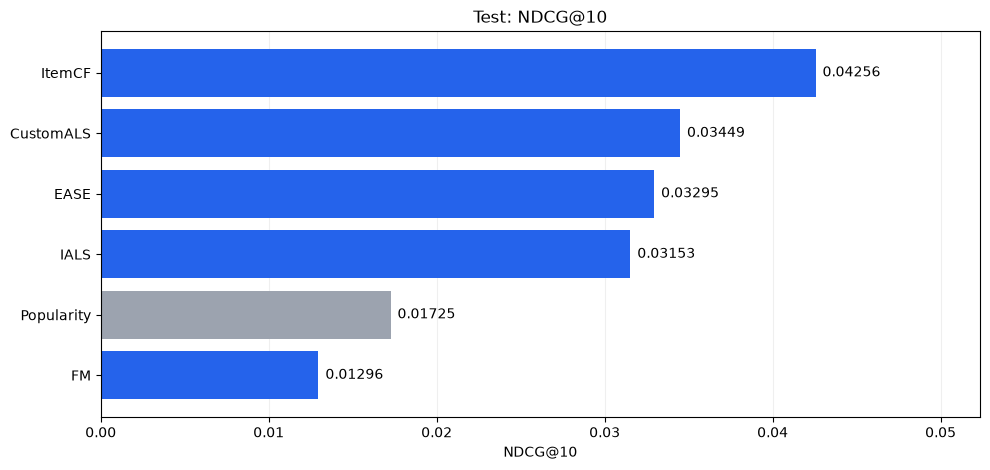

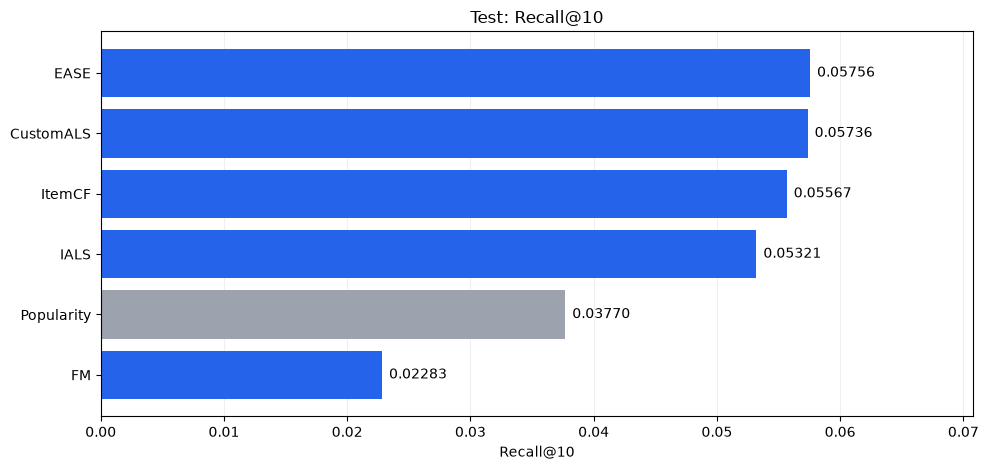

In [17]:
for metric, filename in [("NDCG@10", "test_ndcg10.png"), ("Recall@10", "test_recall10.png")]:
    ordered = final_results_df.sort(metric)
    names = ordered["Model"].to_list()
    values = ordered[metric].to_numpy()
    colors = ["#9ca3af" if name == "Popularity" else "#2563eb" for name in names]

    fig, ax = plt.subplots(figsize=(10, 4.8))
    bars = ax.barh(names, values, color=colors)
    ax.bar_label(bars, labels=[f"{value:.5f}" for value in values], padding=5)
    ax.set_xlim(0, float(values.max()) * 1.23)
    ax.set_xlabel(metric)
    ax.set_title(f"Test: {metric}")
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


## Выводы

Лучший NDCG@10 у ItemCF с Жаккардом и 100 соседями - 0.042557.
По Recall@10 немного лучше EASE - 0.057563.

Кастомный таргет улучшил NDCG@10 относительно iALS с 0.031530
до 0.034488. Значит, в этом эксперименте слабые просмотры дали
полезный дополнительный сигнал.

FM с категориями получила NDCG@10 0.012961 - ниже Popularity
(0.017253). Категории сами по себе не гарантируют лучшего результата;
отдельного сравнения FM без категорий здесь нет.

Все модели оценивались на 1037 пользователях. Результаты относятся к выбранным
пользователям и популярным видео, поэтому на всём датасете они могут отличаться.
